# 05 · Fine-tune the face-quality model on team photos **and recorded video** (v3)

**Why.** `04_finetune_team.ipynb` (v2) fine-tuned on 69 enrolment photos of 3 people with synthetic damage. It
memorised them: team-train Spearman 0.84 → 0.96 while the held-out people stayed at about 0.62. On the held-out people
it was within noise of v1 (Spearman 0.621 vs 0.583, EDC pAUC 44.00 vs 44.18). The cause is too little in-domain data
(`.agents/FACE_QUALITY.md` §10). This notebook adds **real camera faces** cut from the 8 recorded takes
(`AppliedML/video data/{attendance_cam, cam_1, cam_2}`): real blur, distance, light and angles, at no labelling cost.

**Who is who in a video frame.** The labels come from the team recogniser, so naming the faces with that same model
would bias them: only the frames it already recognises would get in. The faces are therefore named with an
**independent model, OpenCV's SFace**, against each person's enrolment photos. A face counts only when SFace is sure
(cosine ≥ 0.40, at least 0.06 above the runner-up). Then **track voting** names every face in a person track
(`ml/tracking`, YOLO11n + ByteTrack, packed in `video_tracks.json`) when at least 3 of its faces are sure and at least
80 % of those agree. This also includes the blurred, small or turned faces SFace could not name on their own, which
are exactly the hard cases the model must learn.

**Labels**: the team recogniser's cosine between the video crop (the app's `crop_face` rule) and the mean of that
person's enrolment photos, which is what the app matches against. Rescaled with v1's percentiles.

**Everything else as in 04**: split by person (held out: Hồng Minh, Mai Chi), fine-tune from v1, half team / half
Kaggle per batch, framing / flip / colour augmentation, last epoch kept.

**Threshold.** 04's rule degenerated on a small set (0.81, accepting 12 % of clean photos). Here the threshold is
chosen for **usability**: the 10th percentile of v3's score on the held-out people's clean enrolment photos, so 90 %
of good photos pass. The notebook reports how much that threshold lowers recognition failures among the accepted
video faces; v1's rule is still reported for comparison.

Outputs: `face_quality_v3.pt` (v1 and v2 untouched), `results_v3.json`, `figures/v3_*.png`. No face images are
displayed or saved.

Inputs on Drive: as for 04, plus `repo/ml/face_quality/video_tracks.json` (from `build_video_tracks.py`) and the
`AppliedML` shortcut in My Drive (it holds `video data/`).

In [1]:
import sys
try:
    import pillow_heif  # noqa: F401  (iPhone HEIC photos)
except ImportError:
    import subprocess; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pillow-heif"], check=True)
import csv, json, os, time, importlib.util, unicodedata, urllib.request
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

try:
    import google.colab  # noqa: F401
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/face_quality_colab")
    REPO, LABELS = BASE / "repo", BASE / "labels"
    TEAM_CANDIDATES = [Path("/content/drive/MyDrive/AppliedML"), BASE / "team_photos"]
    CACHE = Path("/content")
except ImportError:
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".agents").is_dir())
    LABELS = REPO / "data" / "raw" / "face_quality" / "labels"
    TEAM_CANDIDATES = [REPO / "AppliedML"]
    CACHE = REPO / "data" / "raw" / "face_quality"
TEAM = next((p for p in TEAM_CANDIDATES if p.is_dir()), None)
assert TEAM is not None, f"team photos not found in {TEAM_CANDIDATES}: add the AppliedML shortcut to My Drive"
VIDEOS = TEAM / "video data"
assert VIDEOS.is_dir(), f"{VIDEOS} not found"
nfc = lambda t: unicodedata.normalize("NFC", t)   # Drive may store Vietnamese names decomposed (NFD)
NOT_PEOPLE = {"student_card_image", "video data"}
PERSON_DIR = {nfc(p.name): p for p in TEAM.iterdir() if p.is_dir() and nfc(p.name) not in NOT_PEOPLE}
PEOPLE = sorted(PERSON_DIR)
TEST_PEOPLE = [nfc(t) for t in ("Hồng Minh", "Mai Chi")]   # same held-out people as 04
assert set(TEST_PEOPLE) <= set(PEOPLE), (TEST_PEOPLE, PEOPLE)

SEED, VARIANTS = 30082, 12
BASE_PX, FACE_PX = 384, 160          # photos: damage on a 384 px view with the face box 160 px tall (as 04)
VIDEO_FPS, VIDEO_MIN_FACE, CAP_PER_TRACK = 3.0, 32, 40
SF_MIN, SF_MARGIN, VOTE_MIN, VOTE_AGREE = 0.40, 0.06, 3, 0.8
EPOCHS, STEPS_PER_EPOCH, BATCH = 8, 150, 128
LR_BACKBONE, LR_HEAD, WEIGHT_DECAY = 1e-4, 3e-4, 1e-4
rng = np.random.default_rng(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load(feature):
    spec = importlib.util.spec_from_file_location(feature, REPO / "ml" / feature / "infer.py")
    mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod); return mod
recogniser, quality = load("face_recognition"), load("face_quality")
sys.path.insert(0, str(REPO / "ml" / "face_quality"))
from damage import DAMAGES, damage
from heuristic import heuristic_score
assert hasattr(quality, "align_matrix"), "repo/ml/face_quality/infer.py on Drive is old: upload the current one"

def fetch(name, url):
    p = REPO / "ml" / "face_recognition" / "models" / name
    if p.is_file():
        return p
    p = CACHE / name
    if not p.is_file():
        urllib.request.urlretrieve(url, p)
    return p
ZOO = "https://github.com/opencv/opencv_zoo/raw/main/models/"
YUNET = fetch("face_detection_yunet_2023mar.onnx", ZOO + "face_detection_yunet/face_detection_yunet_2023mar.onnx")
SFACE = fetch("face_recognition_sface_2021dec.onnx", ZOO + "face_recognition_sface/face_recognition_sface_2021dec.onnx")
meta = json.loads((LABELS / "meta.json").read_text(encoding="utf-8"))
P1, P99 = meta["cosine_p1"], meta["cosine_p99"]
REC_THR = recogniser.threshold()
VT = json.loads((REPO / "ml" / "face_quality" / "video_tracks.json").read_text(encoding="utf-8"))
FIG = REPO / "ml" / "face_quality" / "figures"; FIG.mkdir(exist_ok=True)
print("device", device, "| people", PEOPLE, "| test", TEST_PEOPLE, "| takes", len(VT["takes"]), "| recogniser threshold", round(REC_THR, 4))

Mounted at /content/drive
device cuda | people ['Hồng Minh', 'Mai Chi', 'Minh Thành', 'Thuận Minh', 'Đức Mạnh'] | test ['Hồng Minh', 'Mai Chi'] | takes 8 | recogniser threshold 0.6922


## 1. Enrolment photos: damage and labels (as in 04), plus each person's SFace and recogniser reference

The photo crops are built exactly as in 04. In addition, each person's clean photos give two reference means: an
SFace mean, used only to *name* video faces, and a team-recogniser mean, used to *label* them.

In [2]:
det = cv2.FaceDetectorYN.create(str(YUNET), "", (320, 320), 0.6)
sface = cv2.FaceRecognizerSF.create(str(SFACE), "")

def yunet(img):
    det.setInputSize((img.shape[1], img.shape[0]))
    _, f = det.detect(img)
    return [] if f is None else list(f)

def detect(img, width=640):
    """Largest face at the app's detection width: (box, marks, row-on-the-small-image, small image)."""
    k = min(1.0, width / img.shape[1])
    small = img if k == 1.0 else cv2.resize(img, (round(img.shape[1] * k), round(img.shape[0] * k)), interpolation=cv2.INTER_AREA)
    f = yunet(small)
    if not f:
        return None
    f = max(f, key=lambda r: r[2] * r[3])
    return f[:4] / k, [(f[4 + 2 * i] / k, f[5 + 2 * i] / k) for i in range(5)], f, small

def sface_feat(img, row):
    v = sface.feature(sface.alignCrop(img, row))[0]
    return v / np.linalg.norm(v)

def base_image(img, box, marks):
    k = FACE_PX / box[3]
    ex, ey = (marks[0][0] + marks[1][0]) / 2, (marks[0][1] + marks[1][1]) / 2
    m = np.array([[k, 0, BASE_PX * 0.5 - k * ex], [0, k, BASE_PX * 0.45 - k * ey]])
    b = cv2.warpAffine(img, m, (BASE_PX, BASE_PX), flags=cv2.INTER_AREA if k < 1 else cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    pt = lambda x, y: (k * x + m[0, 2], k * y + m[1, 2])
    x, y = pt(box[0], box[1])
    return b, (x, y, box[2] * k, box[3] * k), [pt(*q) for q in marks]

def recog_crop(b, box, margin=0.1):
    """backend/app/core/ml_models.crop_face(image, box, "face_recognition"): the box + 10 % margin, not rotated."""
    x, y, w, h = box
    x0, y0 = int(max(0, x - w * margin)), int(max(0, y - h * margin))
    x1, y1 = int(min(b.shape[1], x + w * (1 + margin))), int(min(b.shape[0], y + h * (1 + margin)))
    return b[y0:y1, x0:x1]

def read_photo(path, max_side=1600):
    from PIL import Image, ImageOps
    from pillow_heif import register_heif_opener
    register_heif_opener()
    rgb = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    rgb.thumbnail((max_side, max_side))
    return np.asarray(rgb)[:, :, ::-1].copy()

def label_of(c):
    return float(np.clip((c - P1) / (P99 - P1), 0, 1))

PHOTO_EXT = {".jpg", ".jpeg", ".png", ".heic", ".heif"}
kinds = list(DAMAGES)
samples, skipped = [], []
sf_ref, rec_ref = {}, {}
for person in PEOPLE:
    files = sorted(f for f in PERSON_DIR[person].iterdir()
                   if f.suffix.lower() in PHOTO_EXT and not f.name.lower().startswith("fake"))
    sfs, recs = [], []
    for f in files:
        try:
            img = read_photo(f)
        except Exception as e:  # noqa: BLE001
            skipped.append(f"{person}/{f.name} ({e})"); continue
        found = detect(img)
        if found is None:
            skipped.append(f"{person}/{f.name}"); continue
        box, marks, row, small = found
        sfs.append(sface_feat(small, row))
        b, bbox, bmarks = base_image(img, box, marks)
        versions = [("clean", 0.0, b)] + [(k, lv, damage(b, k, lv, rng)) for k, lv in
                    zip(rng.choice(kinds, VARIANTS), rng.uniform(0.1, 0.9, VARIANTS))]
        for kind, level, im in versions:
            e = recogniser.embed(recog_crop(im, bbox))
            if kind == "clean":
                recs.append(e)
            samples.append(dict(person=person, photo=f.name, source="photo", damage=str(kind), level=float(level),
                                image=quality.align_crop(im, bmarks), emb=e, face_px=float(bbox[3])))
    sf_ref[person] = np.mean(sfs, 0) / np.linalg.norm(np.mean(sfs, 0))
    rec_ref[person] = np.stack(recs)
# photo labels: leave-one-out mean of the person's other clean photos (rule of 01 / 04)
for s in samples:
    ref = rec_ref[s["person"]]
    clean_photos = [x["photo"] for x in samples if x["person"] == s["person"] and x["damage"] == "clean"]
    others = ref[[p != s["photo"] for p in clean_photos]]
    c = others.mean(0); c /= np.linalg.norm(c)
    s["cos"] = float(s["emb"] @ c); s["label"] = label_of(s["cos"])
print({p: len(rec_ref[p]) for p in PEOPLE}, "clean photos per person;", len(samples), "photo crops;", len(skipped), "photos skipped")

{'Hồng Minh': 13, 'Mai Chi': 13, 'Minh Thành': 27, 'Thuận Minh': 28, 'Đức Mạnh': 14} clean photos per person; 1235 photo crops; 13 photos skipped


## 2. Real camera faces from the recorded takes

The recorded videos are sampled at 3 fps, and YuNet runs on the full 1280×720 frame (faces of at least 32 px; the
classroom camera sees small faces). Each face is matched to the person track whose box contains it (keyframe within
0.5 s, face centre in the upper half of the box) and named by SFace or by track vote, as described at the top. Crops
are cut the way the app cuts a frame: `align_crop` for quality, `crop_face` for the recogniser. At most 40 faces are
kept per track, evenly spread over time.

In [3]:
SF_NAMES = list(sf_ref); SF_G = np.stack([sf_ref[p] for p in SF_NAMES])

def track_at(tracks, t, cx, cy):
    """Id of the smallest track box (normalised) at time t that holds the face centre in its upper half."""
    best = None
    for tr in tracks:
        kf = tr["kf"]
        i = min(range(len(kf)), key=lambda j: abs(kf[j][0] - t))
        if abs(kf[i][0] - t) > 0.5:
            continue
        _, x, y, w, h = kf[i]
        if x <= cx <= x + w and y <= cy <= y + h * 0.5 and (best is None or w * h < best[1]):
            best = (tr["id"], w * h)
    return None if best is None else best[0]

faces_v = []           # every detected video face, named or not
t0 = time.time()
for take in VT["takes"]:
    for cam, fname in take["files"].items():
        path = VIDEOS / cam / fname
        if not path.is_file():
            print("missing", path); continue
        cap = cv2.VideoCapture(str(path)); nxt = 0.0; tracks = take["tracks"].get(cam, [])
        while True:
            ok, fr = cap.read()
            if not ok:
                break
            t = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000
            if t < nxt:
                continue
            nxt = t + 1 / VIDEO_FPS
            H, W = fr.shape[:2]
            for row in yunet(fr):
                if row[3] < VIDEO_MIN_FACE:
                    continue
                s = SF_G @ sface_feat(fr, row); o = np.argsort(-s)
                sure = SF_NAMES[o[0]] if s[o[0]] >= SF_MIN and s[o[0]] - s[o[1]] >= SF_MARGIN else None
                box, marks = row[:4], [(row[4 + 2 * i], row[5 + 2 * i]) for i in range(5)]
                tid = track_at(tracks, t, (box[0] + box[2] / 2) / W, (box[1] + box[3] / 2) / H)
                faces_v.append(dict(take=take["take"], cam=cam, t=round(t, 2), track=None if tid is None else (take["take"], cam, tid),
                                    sure=sure, image=quality.align_crop(fr, marks), emb=recogniser.embed(recog_crop(fr, box)),
                                    face_px=float(box[3])))
print(f"{len(faces_v)} video faces in {time.time() - t0:.0f} s; SFace sure on {sum(f['sure'] is not None for f in faces_v)}")

# track vote
votes = defaultdict(Counter)
for f in faces_v:
    if f["track"] is not None and f["sure"]:
        votes[f["track"]][f["sure"]] += 1
track_name = {}
for k, c in votes.items():
    name, n = c.most_common(1)[0]
    if sum(c.values()) >= VOTE_MIN and n / sum(c.values()) >= VOTE_AGREE:
        track_name[k] = name
for f in faces_v:
    f["person"] = track_name.get(f["track"]) if f["track"] is not None else f["sure"]
    f["named_by"] = "track" if f["track"] in track_name else ("sface" if f["track"] is None and f["sure"] else None)
named = [f for f in faces_v if f["person"]]
by_track = defaultdict(list)
for f in named:
    by_track[f["track"] or (f["take"], f["cam"], "untracked", f["person"])].append(f)
video = []
for k, fs in by_track.items():
    fs.sort(key=lambda f: f["t"])
    video += [fs[i] for i in np.unique(np.linspace(0, len(fs) - 1, min(CAP_PER_TRACK, len(fs))).round().astype(int))]
for f in video:
    c = rec_ref[f["person"]].mean(0); c /= np.linalg.norm(c)
    f["cos"] = float(f["emb"] @ c); f["label"] = label_of(f["cos"])
    f.update(source="video", damage=f"video_{f['cam']}", level=0.0, photo=f"take{f['take']}_{f['cam']}_{f['t']}")
print(f"named {len(named)} faces ({sum(f['named_by'] == 'track' for f in named)} by track vote, of which "
      f"{sum(f['named_by'] == 'track' and not f['sure'] for f in named)} SFace could not name alone); "
      f"kept {len(video)} after the per-track cap")
print("video faces per person and camera:")
for p in PEOPLE:
    print(f"  {p:12s}", dict(Counter(f["cam"] for f in video if f["person"] == p)))
lab = np.array([f["label"] for f in video]); px = np.array([f["face_px"] for f in video])
for cam in ("attendance_cam", "cam_1", "cam_2"):
    i = np.array([f["cam"] == cam for f in video])
    if i.any():
        print(f"  {cam:15s} n {i.sum():4d}  face px median {np.median(px[i]):5.0f}  mean label {lab[i].mean():.3f}  "
              f"recognised (cos >= thr) {np.mean([f['cos'] >= REC_THR for f, ii in zip(video, i) if ii]):.0%}")

1498 video faces in 301 s; SFace sure on 453
named 707 faces (698 by track vote, of which 298 SFace could not name alone); kept 625 after the per-track cap
video faces per person and camera:
  Hồng Minh    {'attendance_cam': 88, 'cam_1': 20, 'cam_2': 113}
  Mai Chi      {'attendance_cam': 16}
  Minh Thành   {}
  Thuận Minh   {'cam_2': 142, 'attendance_cam': 49}
  Đức Mạnh     {'cam_2': 123, 'attendance_cam': 44, 'cam_1': 30}
  attendance_cam  n  197  face px median   208  mean label 0.610  recognised (cos >= thr) 51%
  cam_1           n   50  face px median    54  mean label 0.480  recognised (cos >= thr) 12%
  cam_2           n  378  face px median    53  mean label 0.488  recognised (cos >= thr) 12%


In [4]:
# check the naming: SFace's sure names vs the track vote, and against the names ml/tracking gave on takes 1 and 3
agree = [f["sure"] == f["person"] for f in named if f["sure"] and f["named_by"] == "track"]
print(f"inside voted tracks, SFace's own sure name agrees with the track name on {np.mean(agree):.1%} of {len(agree)} faces")
print("tracks named:", len(track_name), "of", len(votes), "tracks with any sure vote")

all_s = samples + video
team_x = np.stack([s["image"] for s in all_s])
team_y = np.array([s["label"] for s in all_s], np.float32)
team_cos = np.array([s["cos"] for s in all_s], np.float32)
team_kind = np.array([s["damage"] for s in all_s])
team_src = np.array([s["source"] for s in all_s])
team_test = np.array([s["person"] in TEST_PEOPLE for s in all_s])
team_tr, team_te = np.where(~team_test)[0], np.where(team_test)[0]

def spearman(a, b):
    ra, rb = np.argsort(np.argsort(a)), np.argsort(np.argsort(b))
    return float(np.corrcoef(ra, rb)[0, 1])

print(f"train: {np.sum(~team_test & (team_src == 'photo'))} photo crops + {np.sum(~team_test & (team_src == 'video'))} video faces "
      f"({sorted(set(PEOPLE) - set(TEST_PEOPLE))})")
print(f"test:  {np.sum(team_test & (team_src == 'photo'))} photo crops + {np.sum(team_test & (team_src == 'video'))} video faces ({TEST_PEOPLE})")

inside voted tracks, SFace's own sure name agrees with the track name on 99.5% of 400 faces
tracks named: 25 of 43 tracks with any sure vote
train: 897 photo crops + 388 video faces (['Minh Thành', 'Thuận Minh', 'Đức Mạnh'])
test:  338 photo crops + 237 video faces (['Hồng Minh', 'Mai Chi'])


## 3. Kaggle data and augmentation (as in 04)

In [5]:
k_images = np.load(LABELS / "images.npy")
k_rows = list(csv.DictReader((LABELS / "labels.csv").open(encoding="utf-8")))
k_y = np.array([float(r["label"]) for r in k_rows], np.float32)
k_split = np.array([r["split"] for r in k_rows])
k_tr, k_va = np.where(k_split == "train")[0], np.where(k_split == "val")[0]

MEAN = torch.tensor(quality.MEAN, device=device).view(1, 3, 1, 1); STD = torch.tensor(quality.STD, device=device).view(1, 3, 1, 1)
S = quality.INPUT_SIZE

def to_tensor(arr):
    x = torch.from_numpy(np.ascontiguousarray(arr[..., ::-1])).permute(0, 3, 1, 2).float().to(device) / 255
    return F.interpolate(x, size=(S, S), mode="bilinear", align_corners=False, antialias=True)

def augment(x):
    """Framing (scale 0.88-1.12, shift +-6 %, rotation +-8 deg), flip, mild colour jitter. Label-preserving."""
    n = len(x)
    s = torch.empty(n, device=device).uniform_(0.88, 1.12)
    r = torch.empty(n, device=device).uniform_(-8, 8) * np.pi / 180
    t = torch.empty(n, 2, device=device).uniform_(-0.12, 0.12)
    theta = torch.stack([torch.stack([torch.cos(r) / s, -torch.sin(r) / s, t[:, 0]], 1),
                         torch.stack([torch.sin(r) / s, torch.cos(r) / s, t[:, 1]], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="border", align_corners=False)
    flip = torch.rand(n, device=device) < 0.5
    x[flip] = x[flip].flip(-1)
    b = torch.empty(n, 1, 1, 1, device=device).uniform_(0.85, 1.15)
    c = torch.empty(n, 1, 1, 1, device=device).uniform_(0.85, 1.15)
    g = x.mean((1, 2, 3), keepdim=True)
    x = (x - g) * c + g * b
    grey = x.mean(1, keepdim=True)
    sat = torch.empty(n, 1, 1, 1, device=device).uniform_(0.8, 1.2)
    return (grey + (x - grey) * sat).clamp(0, 1)

def norm(x):
    return ((x - MEAN) / STD).contiguous()

## 4. Fine-tune from v1

In [6]:
v1 = torch.load(REPO / "ml" / "face_quality" / "face_quality.pt", map_location="cpu", weights_only=True)
model = quality.build_model().to(device); model.load_state_dict(v1["state_dict"])
v1_model = quality.build_model().to(device); v1_model.load_state_dict(v1["state_dict"]); v1_model.eval()
v2_path = REPO / "ml" / "face_quality" / "face_quality_v2.pt"
v2_model = None
if v2_path.is_file():
    v2_model = quality.build_model().to(device)
    v2_model.load_state_dict(torch.load(v2_path, map_location="cpu", weights_only=True)["state_dict"]); v2_model.eval()

head = list(model.classifier.parameters()); head_ids = {id(p) for p in head}
opt = torch.optim.AdamW([{"params": [p for p in model.parameters() if id(p) not in head_ids], "lr": LR_BACKBONE},
                         {"params": head, "lr": LR_HEAD}], weight_decay=WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[LR_BACKBONE, LR_HEAD], total_steps=EPOCHS * STEPS_PER_EPOCH, pct_start=0.15)
loss_fn = nn.HuberLoss(delta=0.1)

def predict(net, arr):
    net.eval(); out = []
    with torch.inference_mode():
        for i in range(0, len(arr), 512):
            out.append(net(norm(to_tensor(arr[i:i + 512])))[:, 0].float().cpu().numpy())
    return np.concatenate(out)

k_va_s = rng.choice(k_va, min(2000, len(k_va)), replace=False)
te_video = team_te[team_src[team_te] == "video"]
history = []
for epoch in range(1, EPOCHS + 1):
    t0, total = time.time(), 0.0
    model.train()
    for _ in range(STEPS_PER_EPOCH):
        it, ik = rng.choice(team_tr, BATCH // 2), rng.choice(k_tr, BATCH // 2)
        x = augment(torch.cat([to_tensor(team_x[it]), to_tensor(k_images[ik])]))
        t = torch.from_numpy(np.concatenate([team_y[it], k_y[ik]])).to(device)
        loss = loss_fn(model(norm(x))[:, 0], t)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step(); total += loss.item()
    h = dict(epoch=epoch, train_loss=total / STEPS_PER_EPOCH,
             team_train_spearman=spearman(predict(model, team_x[team_tr]), team_y[team_tr]),
             kaggle_val_spearman=spearman(predict(model, k_images[k_va_s]), k_y[k_va_s]),
             team_test_spearman=spearman(predict(model, team_x[team_te]), team_y[team_te]),           # watched only
             team_test_video_spearman=spearman(predict(model, team_x[te_video]), team_y[te_video]) if len(te_video) > 3 else None,
             seconds=time.time() - t0)
    history.append(h)
    print(f"epoch {epoch}  loss {h['train_loss']:.4f}  team-train {h['team_train_spearman']:.3f}  Kaggle-val {h['kaggle_val_spearman']:.3f}  "
          f"team-test {h['team_test_spearman']:.3f}  (video {h['team_test_video_spearman']})  ({h['seconds']:.0f} s)")
print("the last epoch is kept (fixed schedule; nothing is selected on the test people)")

epoch 1  loss 0.0078  team-train 0.772  Kaggle-val 0.716  team-test 0.563  (video 0.44237630688404944)  (11 s)
epoch 2  loss 0.0058  team-train 0.865  Kaggle-val 0.719  team-test 0.500  (video 0.20797643236655314)  (10 s)
epoch 3  loss 0.0051  team-train 0.909  Kaggle-val 0.720  team-test 0.519  (video 0.28266646714467814)  (9 s)
epoch 4  loss 0.0047  team-train 0.920  Kaggle-val 0.722  team-test 0.507  (video 0.2161273863761338)  (10 s)
epoch 5  loss 0.0047  team-train 0.933  Kaggle-val 0.727  team-test 0.526  (video 0.26837209889319386)  (10 s)
epoch 6  loss 0.0045  team-train 0.938  Kaggle-val 0.724  team-test 0.525  (video 0.2789677982327881)  (9 s)
epoch 7  loss 0.0043  team-train 0.940  Kaggle-val 0.725  team-test 0.518  (video 0.2774822007756117)  (10 s)
epoch 8  loss 0.0043  team-train 0.941  Kaggle-val 0.725  team-test 0.521  (video 0.2828629842840376)  (10 s)
the last epoch is kept (fixed schedule; nothing is selected on the test people)


## 5. Evaluation on the held-out people

Three views: **real video faces** (the main result, because these are camera frames), photo crops with synthetic
damage, and everything together. The EDC-style curve counts a *recognition failure* when the crop's cosine to the
person's enrolment mean is below the recogniser threshold; discarding low-scored crops first should lower it.

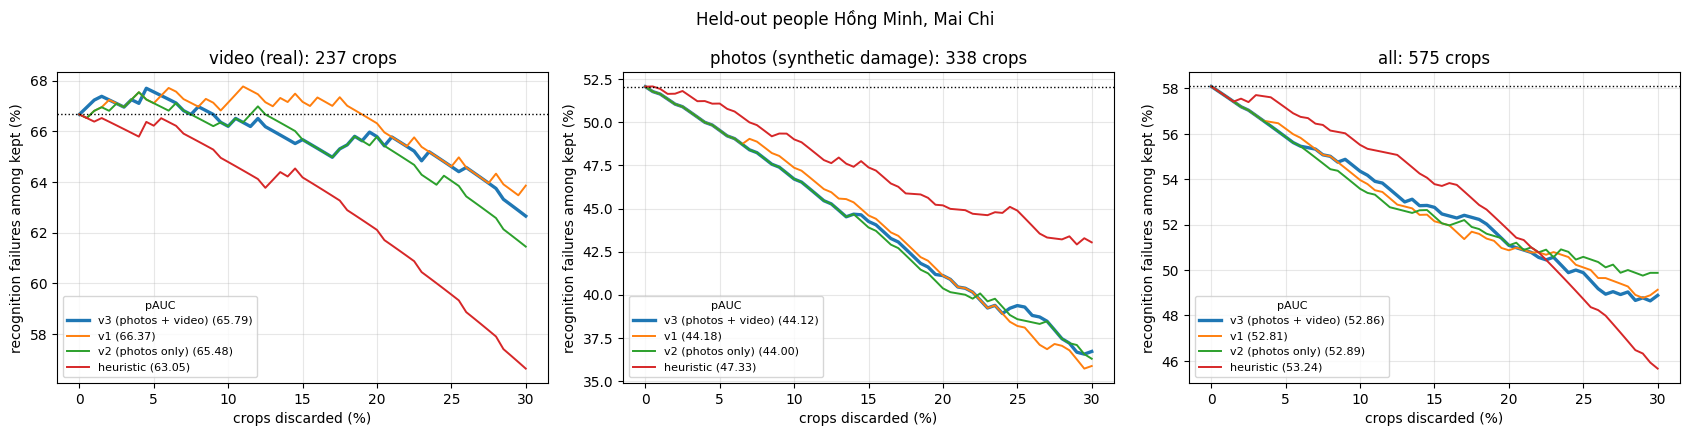

video (real)  (n 237, failures with nothing discarded 66.7%)
   v3 (photos + video)    Spearman +0.283   EDC pAUC 65.79
   v1                     Spearman +0.336   EDC pAUC 66.37
   v2 (photos only)       Spearman +0.434   EDC pAUC 65.48
   heuristic              Spearman +0.570   EDC pAUC 63.05
photos (synthetic damage)  (n 338, failures with nothing discarded 52.1%)
   v3 (photos + video)    Spearman +0.625   EDC pAUC 44.12
   v1                     Spearman +0.583   EDC pAUC 44.18
   v2 (photos only)       Spearman +0.621   EDC pAUC 44.00
   heuristic              Spearman +0.241   EDC pAUC 47.33
all  (n 575, failures with nothing discarded 58.1%)
   v3 (photos + video)    Spearman +0.521   EDC pAUC 52.86
   v1                     Spearman +0.352   EDC pAUC 52.81
   v2 (photos only)       Spearman +0.448   EDC pAUC 52.89
   heuristic              Spearman +0.390   EDC pAUC 53.24
Kaggle val Spearman: {'v3 (photos + video)': 0.725, 'v1': 0.723, 'v2 (photos only)': 0.725}


In [7]:
def edc(score, fail, max_discard=0.30, steps=61):
    order = np.argsort(score)
    xs = np.linspace(0, max_discard, steps)
    ys = np.array([fail[order[int(round(x * len(score))):]].mean() for x in xs])
    return xs, ys, float(getattr(np, "trapezoid", getattr(np, "trapz", None))(ys, xs) / max_discard)

nets = {"v3 (photos + video)": model, "v1": v1_model}
if v2_model is not None:
    nets["v2 (photos only)"] = v2_model
res = {"test_people": TEST_PEOPLE, "recogniser_threshold": REC_THR,
       "data": {"train_photo_crops": int(np.sum(~team_test & (team_src == "photo"))), "train_video_faces": int(np.sum(~team_test & (team_src == "video"))),
                "test_photo_crops": int(np.sum(team_test & (team_src == "photo"))), "test_video_faces": int(np.sum(team_test & (team_src == "video"))),
                "video_faces_detected": len(faces_v), "video_faces_named": len(named), "tracks_named": len(track_name)},
       "views": {}}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, (view, sel) in zip(axes, [("video (real)", team_src[team_te] == "video"), ("photos (synthetic damage)", team_src[team_te] == "photo"),
                                   ("all", np.ones(len(team_te), bool))]):
    idx = team_te[sel]
    if len(idx) < 10:
        ax.set_title(f"{view}: too few crops"); continue
    fail = team_cos[idx] < REC_THR
    sc = {name: predict(net, team_x[idx]) for name, net in nets.items()}
    sc["heuristic"] = np.array([heuristic_score(cv2.resize(team_x[i], (112, 112)), all_s[i]["face_px"]) for i in idx])
    res["views"][view] = {"n": int(len(idx)), "failure_rate_at_0": float(fail.mean()), "methods": {}}
    for name, s in sc.items():
        xs, ys, pauc = edc(s, fail)
        ax.plot(xs * 100, ys * 100, lw=2.4 if name.startswith("v3") else 1.4, label=f"{name} ({pauc * 100:.2f})")
        res["views"][view]["methods"][name] = dict(spearman=spearman(s, team_y[idx]), pAUC_0_30=pauc)
    ax.axhline(fail.mean() * 100, color="k", ls=":", lw=1)
    ax.set_title(f"{view}: {len(idx)} crops"); ax.set_xlabel("crops discarded (%)"); ax.set_ylabel("recognition failures among kept (%)")
    ax.legend(fontsize=8, title="pAUC", title_fontsize=8); ax.grid(alpha=.3)
plt.suptitle(f"Held-out people {', '.join(TEST_PEOPLE)}"); plt.tight_layout(); plt.savefig(FIG / "v3_edc_team.png", dpi=130); plt.show()

res["kaggle_val_spearman"] = {name: spearman(predict(net, k_images[k_va_s]), k_y[k_va_s]) for name, net in nets.items()}
for view, r in res["views"].items():
    print(f"{view}  (n {r['n']}, failures with nothing discarded {r['failure_rate_at_0']:.1%})")
    for name, m in r["methods"].items():
        print(f"   {name:22s} Spearman {m['spearman']:+.3f}   EDC pAUC {m['pAUC_0_30'] * 100:.2f}")
print("Kaggle val Spearman:", {k: round(v, 3) for k, v in res["kaggle_val_spearman"].items()})

## 6. Threshold

**Rule used (usability):** the 10th percentile of v3's score on the held-out people's *clean enrolment photos*, so 90 %
of good photos pass. It is then checked on the held-out **video faces**: how many are accepted, and how much lower the
recognition failure rate is among the accepted ones. v1's rule from 03/04 is reported too.

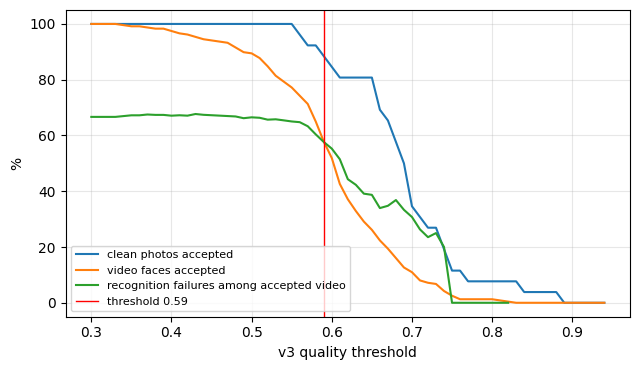

threshold 0.59: clean photos accepted 88%; video faces accepted 58%
recognition failures on held-out video: all 66.7% -> accepted 0.5766423357664233 vs refused 0.79
accepted by camera: {'attendance_cam': '71%', 'cam_1': '25%', 'cam_2': '51%'} | v1's rule would give 0.79


In [8]:
clean_te = team_te[(team_src[team_te] == "photo") & (team_kind[team_te] == "clean")]
s_clean = predict(model, team_x[clean_te])
thr = float(np.round(np.percentile(s_clean, 10), 2))
vid = team_te[team_src[team_te] == "video"]
s_vid = predict(model, team_x[vid]); fail_v = team_cos[vid] < REC_THR
acc = s_vid >= thr
check = dict(video_accepted=float(acc.mean()), video_failure_all=float(fail_v.mean()),
             video_failure_accepted=float(fail_v[acc].mean()) if acc.any() else None,
             video_failure_refused=float(fail_v[~acc].mean()) if (~acc).any() else None,
             clean_photos_accepted=float((s_clean >= thr).mean()),
             by_camera={cam: float(acc[np.array([all_s[i]["cam"] == cam for i in vid])].mean())
                        for cam in ("attendance_cam", "cam_1", "cam_2") if any(all_s[i]["cam"] == cam for i in vid)})
# v1's rule for comparison, on all held-out crops
s_all = predict(model, team_x[team_te]); fail_all = team_cos[team_te] < REC_THR
clean_all = (team_src[team_te] == "photo") & (team_kind[team_te] == "clean")
target = 1.1 * fail_all[clean_all].mean()
v1_rule = next((float(t) for t in np.round(np.arange(0.2, 0.96, 0.01), 2)
                if (s_all >= t).any() and fail_all[s_all >= t].mean() <= target + 1e-9), None)
res["threshold"] = dict(value=thr, rule="10th percentile of v3 score on held-out clean enrolment photos (90 % of good photos pass)",
                        check_on_video=check, v1_rule_value=v1_rule)
ts = np.round(np.arange(0.3, 0.95, 0.01), 2)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(ts, [np.mean(s_clean >= t) * 100 for t in ts], label="clean photos accepted")
ax.plot(ts, [np.mean(s_vid >= t) * 100 for t in ts], label="video faces accepted")
ax.plot(ts, [fail_v[s_vid >= t].mean() * 100 if (s_vid >= t).any() else np.nan for t in ts], label="recognition failures among accepted video")
ax.axvline(thr, color="r", lw=1, label=f"threshold {thr:.2f}"); ax.set_xlabel("v3 quality threshold"); ax.set_ylabel("%")
ax.legend(fontsize=8); ax.grid(alpha=.3); plt.tight_layout(); plt.savefig(FIG / "v3_threshold.png", dpi=130); plt.show()
print(f"threshold {thr:.2f}: clean photos accepted {check['clean_photos_accepted']:.0%}; video faces accepted {check['video_accepted']:.0%}")
print(f"recognition failures on held-out video: all {check['video_failure_all']:.1%} -> accepted {check['video_failure_accepted']} vs refused {check['video_failure_refused']}")
print("accepted by camera:", {k: f"{v:.0%}" for k, v in check["by_camera"].items()}, "| v1's rule would give", v1_rule)

## 7. Save v3 (v1 and v2 stay untouched)

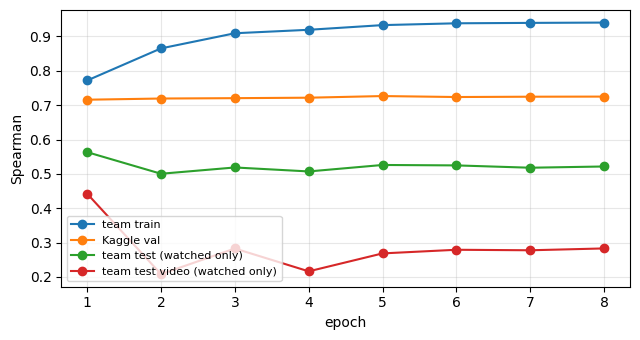

saved face_quality_v3.pt (4.4 MB), results_v3.json, figures v3_*.png
check through infer.py: 0.745 | threshold 0.5899999737739563


In [9]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
e = [h["epoch"] for h in history]
for k, lab_ in (("team_train_spearman", "team train"), ("kaggle_val_spearman", "Kaggle val"),
                ("team_test_spearman", "team test (watched only)"), ("team_test_video_spearman", "team test video (watched only)")):
    if history[0][k] is not None:
        ax.plot(e, [h[k] for h in history], marker="o", label=lab_)
ax.set_xlabel("epoch"); ax.set_ylabel("Spearman"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "v3_training.png", dpi=130); plt.show()

payload = {k: v for k, v in v1.items() if k not in ("state_dict", "history")}
payload.update(state_dict={k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
               threshold=thr, threshold_status="chosen in 05_finetune_video.ipynb: " + res["threshold"]["rule"], threshold_domain="webcam",
               version="v3", parent="v1", history=history,
               training=dict(v1["training"], v3=dict(seed=SEED, epochs=EPOCHS, steps_per_epoch=STEPS_PER_EPOCH, batch=BATCH,
                   mix="half team (photos + video faces) / half Kaggle per batch", lr_backbone=LR_BACKBONE, lr_head=LR_HEAD,
                   augmentation="framing scale 0.88-1.12, shift +-6 %, rotation +-8 deg, flip, brightness/contrast 0.85-1.15, saturation 0.8-1.2",
                   video=dict(fps=VIDEO_FPS, min_face=VIDEO_MIN_FACE, cap_per_track=CAP_PER_TRACK, naming="SFace sure (>= %.2f, margin %.2f) + track vote (>= %d votes, %.0f %% agree)" % (SF_MIN, SF_MARGIN, VOTE_MIN, VOTE_AGREE * 100)),
                   team_train_people=sorted(set(PEOPLE) - set(TEST_PEOPLE)), team_test_people=TEST_PEOPLE,
                   data=res["data"], init="face_quality v1", device=str(device))))
out = REPO / "ml" / "face_quality" / "face_quality_v3.pt"
torch.save(payload, out)
res["history"] = history
(REPO / "ml" / "face_quality" / "results_v3.json").write_text(json.dumps(res, indent=1, ensure_ascii=False), encoding="utf-8")
os.environ["HAWKEYE_FACE_QUALITY_WEIGHTS"] = str(out); quality._state.clear()
print(f"saved {out.name} ({out.stat().st_size / 1e6:.1f} MB), results_v3.json, figures v3_*.png")
print("check through infer.py:", round(quality.score(team_x[team_te[0]]), 4), "| threshold", quality.threshold())